In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/sample_submission.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/train.csv
/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/test.csv


# Importing & Loading the Dataset

In [2]:
df = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/train.csv")
df.drop(['id'], axis=1, inplace=True)

df.head()


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,customer_id,last_name,credit_score,country,gender,age,tenure,acc_balance,prod_count,has_card,is_active,estimated_salary,exit_status
0,15788291,Iredale,559.0,France,Male,28.0,1,149989.39,1.0,1.0,1.0,67622.46,0
1,15642816,Hs?,694.0,France,Female,37.0,7,114510.35,2.0,0.0,0.0,182797.86,0
2,15632272,T'ien,585.0,NaN,Female,45.0,8,NaN,2.0,1.0,1.0,170338.35,0
3,15685826,Hightower,589.0,Spain,Male,25.0,0,166082.18,1.0,1.0,1.0,166476.46,0
4,15658032,Hopkins,701.0,France,Male,39.0,2,0.00,2.0,1.0,0.0,82526.92,0


# Data Types and Descriptive Statistics

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90000 entries, 0 to 89999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       90000 non-null  int64  
 1   last_name         90000 non-null  object 
 2   credit_score      80444 non-null  float64
 3   country           83979 non-null  object 
 4   gender            90000 non-null  object 
 5   age               90000 non-null  float64
 6   tenure            90000 non-null  int64  
 7   acc_balance       82743 non-null  float64
 8   prod_count        85137 non-null  float64
 9   has_card          90000 non-null  float64
 10  is_active         90000 non-null  float64
 11  estimated_salary  90000 non-null  float64
 12  exit_status       90000 non-null  int64  
dtypes: float64(7), int64(3), object(3)
memory usage: 8.9+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,90000.0,1.569209e+07,71297.959941,15565701.00,15633608.00,15690164.00,1.575674e+07,15815690.00
credit_score,80444.0,6.564971e+02,80.016856,350.00,597.00,659.00,7.100000e+02,850.00
age,90000.0,3.811953e+01,8.855203,18.00,32.00,37.00,4.200000e+01,92.00
tenure,90000.0,5.017022e+00,2.804813,0.00,3.00,5.00,7.000000e+00,10.00
acc_balance,82743.0,5.545673e+04,62788.474236,0.00,0.00,0.00,1.198258e+05,250898.09
prod_count,85137.0,1.552932e+00,0.548011,1.00,1.00,2.00,2.000000e+00,4.00
has_card,90000.0,7.542889e-01,0.430510,0.00,1.00,1.00,1.000000e+00,1.00
is_active,90000.0,4.971778e-01,0.499995,0.00,0.00,0.00,1.000000e+00,1.00
estimated_salary,90000.0,1.123947e+05,50360.440702,11.58,74430.36,117505.07,1.548748e+05,199992.48
exit_status,90000.0,2.116000e-01,0.408445,0.00,0.00,0.00,0.000000e+00,1.00


# Missing Values and Duplicates

In [5]:
print ("Missing Values\n")
df.isnull().sum()

Missing Values



customer_id            0
last_name              0
credit_score        9556
country             6021
gender                 0
age                    0
tenure                 0
acc_balance         7257
prod_count          4863
has_card               0
is_active              0
estimated_salary       0
exit_status            0
dtype: int64

In [6]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

df = df.drop_duplicates()
print(f"Shape after removing duplicates: {df.shape}")

Number of duplicate rows: 0
Shape after removing duplicates: (90000, 13)


# Plots

## Box Plot for find outliner.

- Not removing Outliers because they important in these dataset

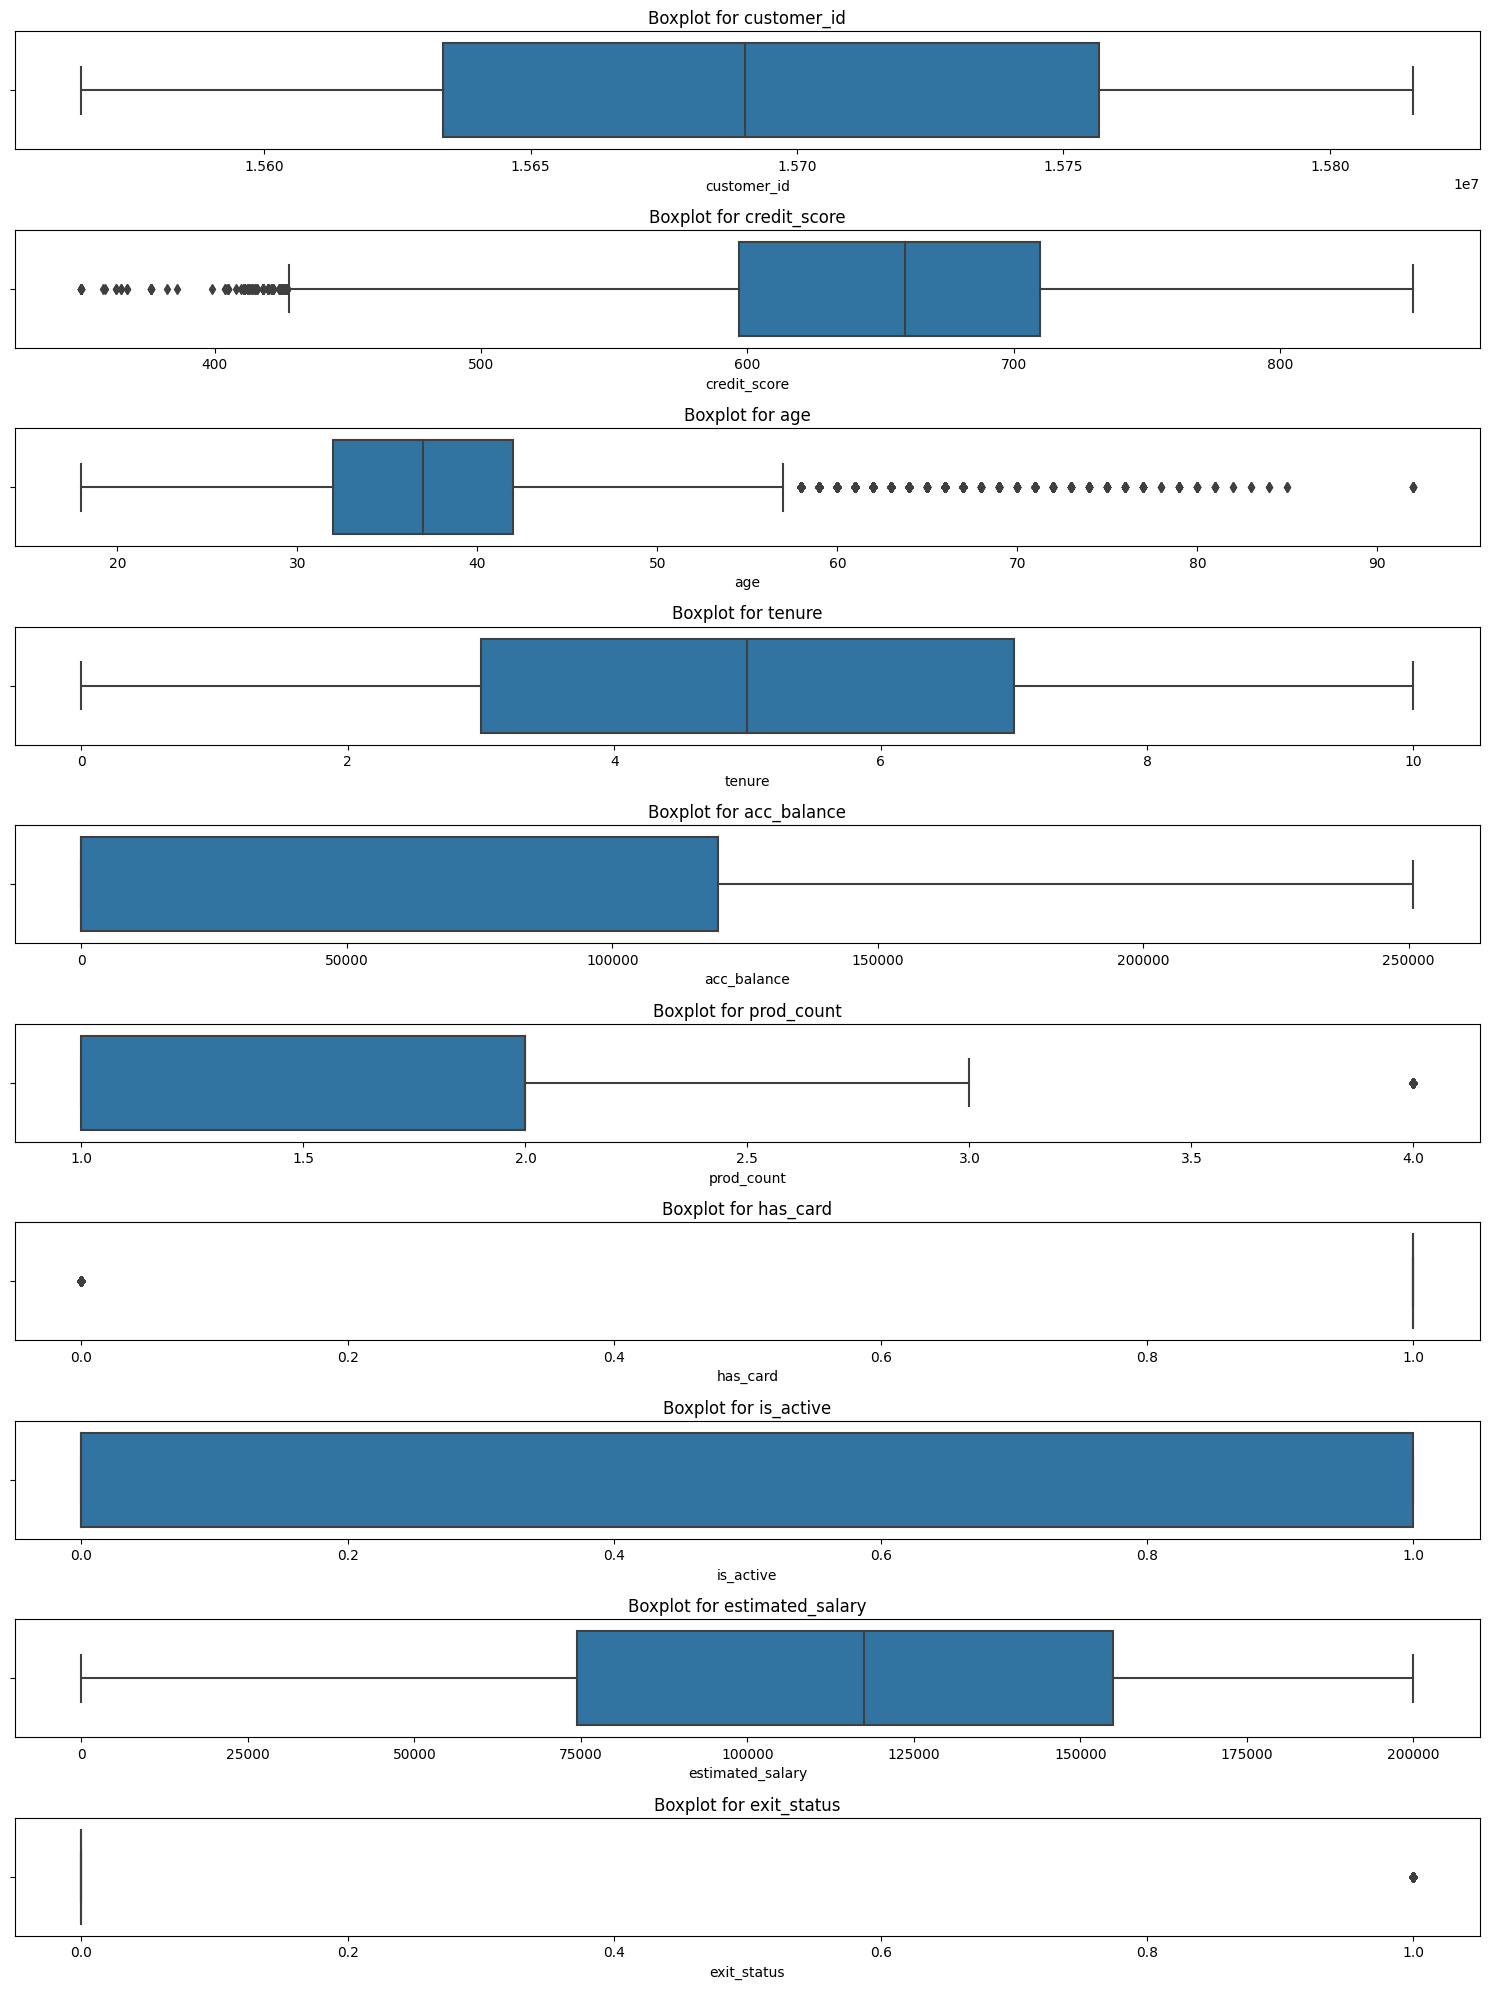

In [7]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(15, 20))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(len(numerical_cols), 1, i)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot for {col}')
plt.tight_layout()
plt.show()

# Outlier detection using IQR
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower) | (df[column] > upper)]
    print(f"{column} - Outliers detected: {len(outliers)}")
    return df[(df[column] >= lower) & (df[column] <= upper)]



## Correlation Matrix of Numericals Values

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


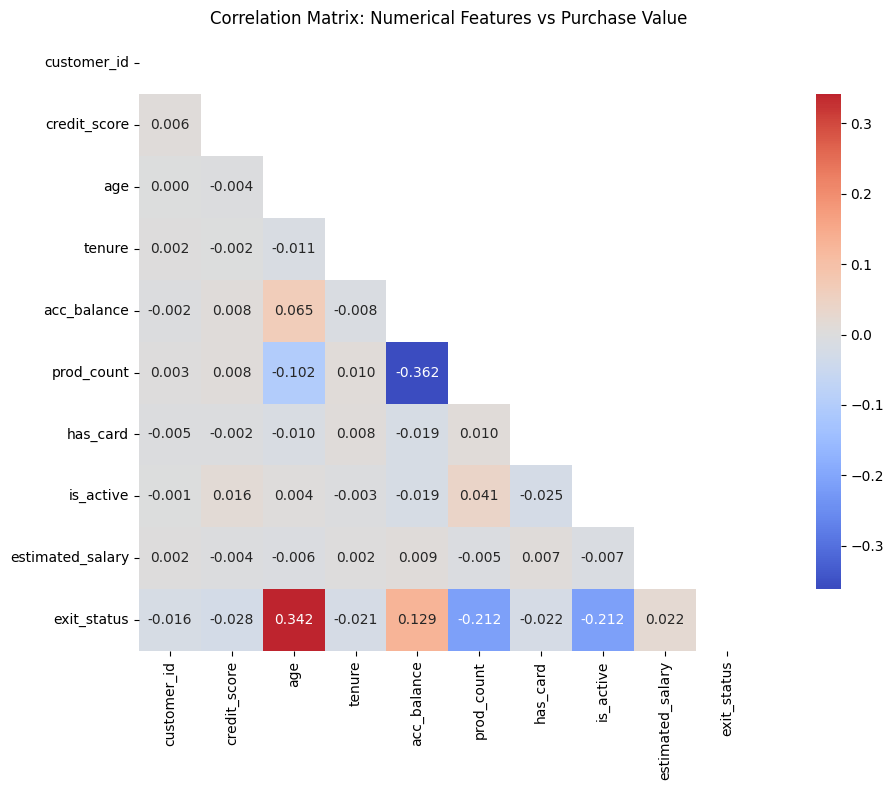

In [8]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.3f', cbar_kws={"shrink": .8})
plt.title('Correlation Matrix: Numerical Features vs Purchase Value')
plt.tight_layout()
plt.show()

## Some other plots

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


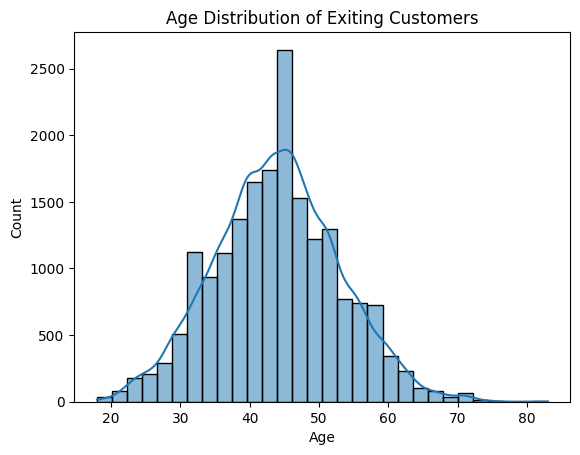

In [9]:
sns.histplot(df[df['exit_status'] == 1]['age'], bins=30, kde=True)
plt.title("Age Distribution of Exiting Customers")
plt.xlabel("Age")
plt.show()

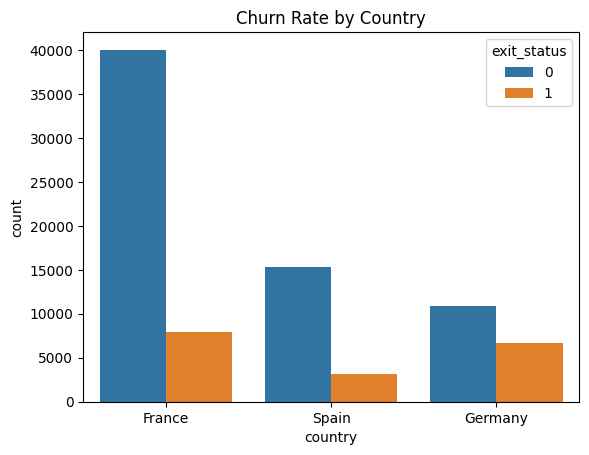

In [10]:
sns.countplot(x='country', hue='exit_status', data=df)
plt.title('Churn Rate by Country')
plt.show()

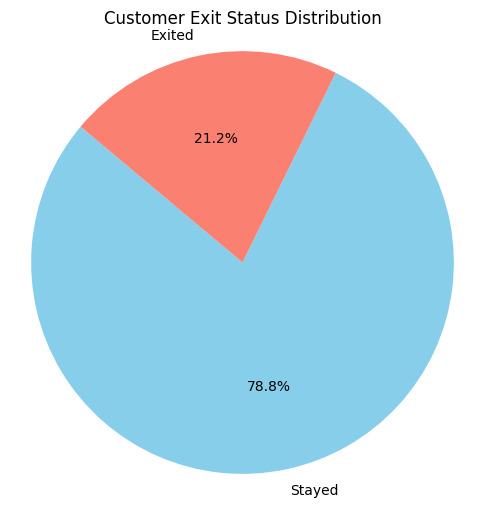

In [11]:
exit_counts = df['exit_status'].value_counts()

labels = ['Stayed', 'Exited']
plt.figure(figsize=(6, 6))
plt.pie(exit_counts, labels=labels, autopct='%1.1f%%', startangle=140, colors=['skyblue', 'salmon'])
plt.title('Customer Exit Status Distribution')
plt.axis('equal')  
plt.show()

# Preprocessing

In [12]:
# PREPROCESSING PIPELINE

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin

print("\n" + "="*60)
print("COMPREHENSIVE PREPROCESSING PIPELINE")
print("="*60)

# 1. Train-Test Split
print("\n1. TRAIN-TEST SPLIT")
print("-"*20)

# Separate features and target
X = df.drop(['customer_id','exit_status'], axis=1)
y = df['exit_status']

X_train, X_test, y_binary_train, y_binary_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training zero rate: {(y_binary_train == 0).mean():.3f}")
print(f"Test zero rate: {(y_binary_test == 0).mean():.3f}")

# 2. Feature Analysis and Categorization
print("\n2. FEATURE PREPROCESSING")
print("-"*25)

# Identify numerical and categorical features
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns.tolist()

print(f"Numerical features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")

# Analyze cardinality for categorical features
for col in categorical_cols:
    unique_count = X_train[col].nunique()
    print(f"  - {col}: {unique_count} unique values")

features_to_drop = ['last_name']  # Too high cardinality, likely not useful
low_cardinality_cats = ['gender']  # <= 10 unique values
print(f"\nFeatures to drop: {features_to_drop}")
print(f"Low cardinality categorical (OneHot): {low_cardinality_cats}")
print(f"Special handling for 'country': impute with 'unknown' + OneHotEncoder")

# 3. Create Preprocessing Pipelines
print("\n3. PREPROCESSING PIPELINES")
print("-"*28)

# Numerical pipeline: Impute with median + StandardScaler
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Country pipeline: Impute with constant 'unknown' + OneHotEncoder
country_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# Low cardinality categorical pipeline: Most frequent imputation + OneHotEncoder
low_cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# Combine all transformers
preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('country', country_pipeline, ['country']),
    ('low_cat', low_cat_pipeline, low_cardinality_cats)
], remainder='drop')  # Drop remaining columns (including last_name)

print("Preprocessing pipeline created successfully!")
print("Pipeline components:")
print("  1. Numerical features: median imputation + StandardScaler")
print("  2. Country: 'unknown' imputation + OneHotEncoder")
print("  3. Gender: most_frequent imputation + OneHotEncoder")
print("  4. High cardinality features (last_name): DROPPED")

# 4. Fit and Transform
print("\n4. FITTING AND TRANSFORMING DATA")
print("-"*35)

# Fit the preprocessor on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Original training shape: {X_train.shape}")
print(f"Processed training shape: {X_train_processed.shape}")
print(f"Original test shape: {X_test.shape}")
print(f"Processed test shape: {X_test_processed.shape}")

# Get feature names after transformation
feature_names = []
# Numerical features
feature_names.extend(numerical_cols)
# Country features (after OneHot)
country_encoder = preprocessor.named_transformers_['country']['onehot']
country_feature_names = [f"country_{name}" for name in country_encoder.get_feature_names_out(['country'])]
feature_names.extend(country_feature_names)
# Gender features (after OneHot)
gender_encoder = preprocessor.named_transformers_['low_cat']['onehot']
gender_feature_names = [f"gender_{name}" for name in gender_encoder.get_feature_names_out(['gender'])]
feature_names.extend(gender_feature_names)

print(f"Total features after preprocessing: {len(feature_names)}")
print(f"Feature names: {feature_names[:10]}..." if len(feature_names) > 10 else f"Feature names: {feature_names}")



COMPREHENSIVE PREPROCESSING PIPELINE

1. TRAIN-TEST SPLIT
--------------------
Training set: 72000 samples
Test set: 18000 samples
Training zero rate: 0.788
Test zero rate: 0.789

2. FEATURE PREPROCESSING
-------------------------
Numerical features (8): ['credit_score', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary']
Categorical features (3): ['last_name', 'country', 'gender']
  - last_name: 2521 unique values
  - country: 3 unique values
  - gender: 2 unique values

Features to drop: ['last_name']
Low cardinality categorical (OneHot): ['gender']
Special handling for 'country': impute with 'unknown' + OneHotEncoder

3. PREPROCESSING PIPELINES
----------------------------
Preprocessing pipeline created successfully!
Pipeline components:
  1. Numerical features: median imputation + StandardScaler
  2. Country: 'unknown' imputation + OneHotEncoder
  3. Gender: most_frequent imputation + OneHotEncoder
  4. High cardinality features (last_name): 

# Model Building

## Initial Selection of Model

In [13]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                           f1_score, roc_auc_score, classification_report, 
                           confusion_matrix, roc_curve)
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, 
                            HistGradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import time


models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Ridge Classifier': RidgeClassifier(random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42, n_estimators=100),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1, class_weight='balanced'),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),

}

results = []
model_predictions = {}
model_probabilities = {}
training_times = {}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\n1. TRAINING AND EVALUATING MODELS")
print("-" * 40)

for name, model in models.items():
    print(f"\nTraining {name}...")
    
    start_time = time.time()
    
    try:
        model.fit(X_train_processed, y_binary_train)
        training_time = time.time() - start_time
        training_times[name] = training_time
        
        y_pred = model.predict(X_test_processed)
        y_prob = model.predict_proba(X_test_processed)[:, 1] if hasattr(model, 'predict_proba') else None
        
        model_predictions[name] = y_pred
        model_probabilities[name] = y_prob
        
        accuracy = accuracy_score(y_binary_test, y_pred)
        precision = precision_score(y_binary_test, y_pred)
        recall = recall_score(y_binary_test, y_pred)
        f1 = f1_score(y_binary_test, y_pred)
        roc_auc = roc_auc_score(y_binary_test, y_prob) if y_prob is not None else None
        
        cv_scores = cross_val_score(model, X_train_processed, y_binary_train, 
                                  cv=cv, scoring='f1', n_jobs=-1)
        cv_mean = cv_scores.mean()
        cv_std = cv_scores.std()
        
        results.append({
            'Model': name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1 Score': f1,
            'ROC AUC': roc_auc,
            'CV F1 Mean': cv_mean,
            'CV F1 Std': cv_std,
            'Training Time (s)': training_time
        })
        
        print(f"  ✓ F1: {f1:.4f}, Accuracy: {accuracy:.4f}, ROC AUC: {roc_auc}")
        
    except Exception as e:
        print(f"  ✗ Failed: {str(e)}")
        continue

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)

print("\n2. PERFORMANCE COMPARISON TABLE")
print("-" * 40)
results_df


1. TRAINING AND EVALUATING MODELS
----------------------------------------

Training Logistic Regression...
  ✓ F1: 0.4806, Accuracy: 0.8313, ROC AUC: 0.8128191755594066

Training Ridge Classifier...
  ✓ F1: 0.4147, Accuracy: 0.8254, ROC AUC: None

Training Decision Tree...
  ✓ F1: 0.5175, Accuracy: 0.7968, ROC AUC: 0.694368089269289

Training Random Forest...
  ✓ F1: 0.5950, Accuracy: 0.8569, ROC AUC: 0.8655120837196988

Training Gradient Boosting...
  ✓ F1: 0.6078, Accuracy: 0.8601, ROC AUC: 0.8791978156146144

Training Hist Gradient Boosting...
  ✓ F1: 0.6154, Accuracy: 0.8608, ROC AUC: 0.8800052496625952

Training XGBoost...
  ✓ F1: 0.6160, Accuracy: 0.8598, ROC AUC: 0.8752048195459579

Training LightGBM...
  ✓ F1: 0.6333, Accuracy: 0.8118, ROC AUC: 0.8797476118611335

Training K-Nearest Neighbors...
  ✓ F1: 0.5793, Accuracy: 0.8447, ROC AUC: 0.8127626745759255

2. PERFORMANCE COMPARISON TABLE
----------------------------------------


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,CV F1 Mean,CV F1 Std,Training Time (s)
0,LightGBM,0.811778,0.536993,0.771564,0.633254,0.879748,0.637115,0.005944,0.569575
1,XGBoost,0.859833,0.728058,0.533896,0.616040,0.875205,0.621131,0.006883,0.441927
2,Hist Gradient Boosting,0.860833,0.736223,0.528620,0.615385,0.880005,0.626389,0.008439,0.857942
3,Gradient Boosting,0.860111,0.742107,0.514640,0.607788,0.879198,0.614576,0.007619,10.612365
4,Random Forest,0.856889,0.736473,0.499077,0.594969,0.865512,0.599683,0.008816,10.280455
5,K-Nearest Neighbors,0.844667,0.674256,0.507782,0.579296,0.812763,0.578860,0.003513,0.166734
6,Decision Tree,0.796833,0.517687,0.517278,0.517483,0.694368,0.520593,0.007864,0.517206
7,Logistic Regression,0.831278,0.683366,0.370615,0.480588,0.812819,0.485737,0.006876,0.292995
8,Ridge Classifier,0.825444,0.705770,0.293590,0.414680,NaN,0.418467,0.007879,0.054176


## Hyperparameter Tuning of Models and Comparison of model performances 

In [14]:
from sklearn.model_selection import StratifiedKFold
from scipy.stats import  randint
from sklearn.model_selection import RandomizedSearchCV
from xgboost.sklearn import XGBClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import SGDClassifier, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier

import warnings

warnings.filterwarnings("ignore")

# Hyperparameter Tuning 3 Model 

model_grids = {
    "LightGBM": (LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1), {
        "max_depth": [10, None],
        'n_estimators': [100, 150, 200],
    }),
    "Hist Gradient Boosting": (HistGradientBoostingClassifier(random_state=42), {
        'learning_rate': np.linspace(0.01, 0.25, 5),
        'max_depth': randint(3, 10),
        'min_samples_leaf': randint(1, 5),
    }),
    "XGBoost": (XGBClassifier(random_state=42, verbosity=0), {
        'n_estimators': randint(100, 300),
        'learning_rate': np.linspace(0.01, 0.25, 10),
        'max_depth': randint(3, 10),
    })
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


results = []
best_models = {}

for name, (model, params) in model_grids.items():
    print(f"\nTraining {name}...")
    if params:
        grid = RandomizedSearchCV(model, params, cv=cv, n_jobs=-1, scoring='f1')
        grid.fit(X_train_processed, y_binary_train)
        best_model = grid.best_estimator_
        print(f"Best Params: {grid.best_params_}")
    else:
        model.fit(X_train_processed, y_binary_train)
        best_model = model

    preds = best_model.predict(X_test_processed)
    r2 = f1_score(y_binary_test, preds)

    results.append([name, r2])
    best_models[name] = best_model

# Results summary
results_df = pd.DataFrame(results, columns=["Model", "f1 Score"])
results_df = results_df.sort_values(by="f1 Score", ascending=False).reset_index(drop=True)
print("\nModel Comparison:")
results_df


Training LightGBM...
Best Params: {'n_estimators': 200, 'max_depth': 10}

Training Hist Gradient Boosting...
Best Params: {'learning_rate': 0.25, 'max_depth': 5, 'min_samples_leaf': 2}

Training XGBoost...
Best Params: {'learning_rate': 0.19666666666666666, 'max_depth': 5, 'n_estimators': 178}

Model Comparison:


,Model,f1 Score
0,LightGBM,0.630366
1,XGBoost,0.618585
2,Hist Gradient Boosting,0.614796


# Final Submission

In [15]:
test_df = pd.read_csv("/kaggle/input/mlp-term-2-2025-kaggle-assignment-2/test.csv")
print(f"Test data shape: {test_df.shape}")
print(f"Test data columns: {list(test_df.columns)}")

# 2. Prepare test features (same preprocessing as training)
print("\n2. PREPROCESSING TEST DATA")
print("-"*25)

# Remove id and customer_id columns (same as training)
test_ids = test_df['id'].copy()  # Save IDs for submission
X_test_final = test_df.drop(['id', 'customer_id'], axis=1)

print(f"Test features shape before preprocessing: {X_test_final.shape}")
print(f"Test features columns: {list(X_test_final.columns)}")

# Apply the same preprocessing pipeline
X_test_final_processed = preprocessor.transform(X_test_final)
print(f"Test features shape after preprocessing: {X_test_final_processed.shape}")

# 3. Generate predictions
print("\n3. GENERATING PREDICTIONS")
print("-"*25)

test_predictions = best_models['LightGBM'].predict(X_test_final_processed)
test_predictions_proba = best_models['LightGBM'].predict_proba(X_test_final_processed)


# 4. Create submission file
print("\n4. CREATING SUBMISSION FILE")
print("-"*27)

# Create submission dataframe
submission_df = pd.DataFrame({
    'id': test_ids,
    'exit_status': test_predictions
})

print(f"Submission dataframe shape: {submission_df.shape}")
print("\nFirst 10 rows of submission:")
print(submission_df.head(10))

submission_filename = "submission.csv"
submission_df.to_csv(submission_filename, index=False)

Test data shape: (30000, 13)
Test data columns: ['id', 'customer_id', 'last_name', 'credit_score', 'country', 'gender', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary']

2. PREPROCESSING TEST DATA
-------------------------
Test features shape before preprocessing: (30000, 11)
Test features columns: ['last_name', 'credit_score', 'country', 'gender', 'age', 'tenure', 'acc_balance', 'prod_count', 'has_card', 'is_active', 'estimated_salary']
Test features shape after preprocessing: (30000, 12)

3. GENERATING PREDICTIONS
-------------------------

4. CREATING SUBMISSION FILE
---------------------------
Submission dataframe shape: (30000, 2)

First 10 rows of submission:
   id  exit_status
0   0            0
1   1            1
2   2            1
3   3            0
4   4            0
5   5            1
6   6            0
7   7            1
8   8            1
9   9            0
